#  <span style="color:#C133FF"> Processing MRI data for $\chi$ -fitting project!</span> 

In [59]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import sys
import pandas as pd
import os
import json
import time

#  <span style="color:#FA3F14"> Processing T1w for simulation</span> 

The first step is to combine the multiple FOVs with Slicer3D

###  <span style="color:#FAF614"> Compact Total Spine Seg output</span> 
After creation of the T1w whole body MRI through stitching, we can run the command

'sct_deepseg spine -i  t1w_wholebody.nii.gz -o totalspineseg.nii.gz'

There will be X amount of outputs and we take the path to totaspineseg_totalspineseg_all.nii.gz and merge the labels into their susceptibility groups

In [4]:
# 
bones = [3,4,5,6,7,17,18,19,20,21,22,23,24,25,35,36,37,38,39,40,41,42,43,44]
cartilage = [8,9,10,11,12,26,27,28,29,30,31,32,33,34,45,46,47,48,49,50,51,52,53]

spinal_structures = [1, 2] # Cord and canal

# List for all bones of the spine
vertebrae = [
    11, 12, 13, 14, 15, 16, 17, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 
    31, 32, 41, 42, 43, 44, 45, 50
]

# List for all the intervertebral discs
discs = [
    63, 64, 65, 66, 67, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 
    91, 92, 93, 94, 95, 100
]

In [3]:
path_to_spineseg = r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\totalspinseg_totalspineseg_all.nii.gz"
spineseg_og_img = nib.load(path_to_spineseg)
spineseg_og_data = spineseg_og_img.get_fdata()
spineseg_og_data.shape

(289, 260, 575)

In [5]:
Size_X=(spineseg_og_data.shape)[0]
Size_Y=(spineseg_og_data.shape)[1]
Size_Z=(spineseg_og_data.shape)[2]

spine_seg_grouped = np.zeros((Size_X,Size_Y,Size_Z))

for i in range(len(spineseg_og_data[:,0,0])):
    for j in range( len(spineseg_og_data[0,:,0])):
        for k in range( len(spineseg_og_data[0,0,:])):

            pixel = spineseg_og_data[i,j,k]

            if pixel in spinal_structures: 
                spine_seg_grouped[i,j,k] = 10 # Spinal cord

            if pixel in vertebrae: 
                spine_seg_grouped[i,j,k]  = 11 # Bones

            if pixel in discs: 
                spine_seg_grouped[i,j,k]  = 12 # Discs

The numbers above don't matter because they will get re-ordered when creating the final whole body phantom with slicer

In [6]:
grouped_spineseg_img = nib.Nifti1Image(spine_seg_grouped, spineseg_og_img.affine)

path_to_spineseg_merged_output =  r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\t1w_wholebody_merged_totalspineseg_all.nii.gz"

nib.save(grouped_spineseg_img, path_to_spineseg_merged_output)

###  <span style="color:#FAF614"> Compact Samseg output</span> 

On a similar note, SAMSEG will provide several regions of the brain, for now we can merge them to 1 individual brain label. Furthemore, this provides the skull label.

In [7]:
path_to_samseg_segs = r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\initial_samseg.nii.gz"
samseg_img = nib.load(path_to_samseg_segs)
samseg_data = np.array(samseg_img.get_fdata())
samseg_data.shape

(192, 260, 320)

In [8]:
# Check the numbers, this might change with new releases
# Last updated for Samseg under freesurfer 8.0.0-beta
samseg_brain_list = [2,3,4,5,7,8,10,11,12,13,14,15,16,17,18,24,26,28,30,31,41,42,43,44,46,47,49,50,51,52,53,54,58,60,62,63,72,77,80,85] #16 is the brainstem
samseg_skull_list = [165]

Size_X=(samseg_data.shape)[0]
Size_Y=(samseg_data.shape)[1]
Size_Z=(samseg_data.shape)[2]

grouped_samseg_data = np.zeros((Size_X,Size_Y,Size_Z))

for i in range(len(samseg_data[:,0,0])):
    for j in range( len(samseg_data[0,:,0])):
        for k in range( len(samseg_data[0,0,:])):

            pixel = samseg_data[i,j,k]
            
            if pixel in samseg_brain_list:
                grouped_samseg_data[i,j,k] = 23
            if pixel in samseg_skull_list:
                grouped_samseg_data[i,j,k] = 25

In [10]:
grouped_samseg_img = nib.Nifti1Image(grouped_samseg_data, samseg_img.affine)
out_path = r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\brain_grouped_seg.nii.gz"
nib.save(grouped_samseg_img, out_path)

###  <span style="color:#FAF614"> Body and air segmentation with custom nnUNetv2</span> 

The initial segmentation of the trachea, lungs, and the body labels is done with a custom nnUNet

You must follow install instructions from nnUNetv2 first: <link>

Once that is done, follow this instructions to set up the trained model (you will need access to the trained model)

Activate the environment and run:

nnUnetv2_predict -i nnunet_input -c 3dfull_res -d 412 -tr nnUNetTrainerFT -p custom_plans730 -f 0 -o nnunet_output

###  <span style="color:#FAF614"> Combining all labels -> Define head-to-thorso phantom </span> 

Once all previous segmentations are finished, we can load them all up in slicer and combine them.

It is crucial to use "Logical Operators" under Segment editor, we need to remove overlap between labels, for example: the body label will overlap with the spinal cord, spinal canal, vertebrae and discs.

Once all overlap is corrected you would have: brain, skull, sinus, ear canal, trachea, vertebra, inter-vert. discs, spinal cord, two lungs, and body labels.

This now need to be sorted into the CANONICAL IDs used with tissue-to-MR-property

The order in which the labels appear in the final slicer output will depend on the actual order of the segmentations, in the following code cell you'll find the if statements where you need to change the if pixel according to what your segmentation file has, for example, for you the Body label could be #6, then you would change that to 6, the assignment of the new pixel value uses the CANONICAL IDs (version XXXX)

In [22]:
final_labels_img = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\final_merged_wb_segs.nii.gz")
final_labels_data = final_labels_img.get_fdata()

Size_X=(final_labels_data.shape)[0]
Size_Y=(final_labels_data.shape)[1]
Size_Z=(final_labels_data.shape)[2]

final_segmentations_converter = np.zeros((Size_X,Size_Y,Size_Z))

for i in range(len(final_labels_data[:,0,0])):
    for j in range( len(final_labels_data[0,:,0])):
        for k in range( len(final_labels_data[0,0,:])):

            pixel = final_labels_data[i,j,k]
            final_pixel = final_segmentations_converter[i,j,k]

            if pixel == 2: # Body label DONE
                final_segmentations_converter[i,j,k] = 264

            if pixel == 25: # Bone from skull DONE
                final_segmentations_converter[i,j,k] = 10

            if pixel == 3: # Bone from spine DONE
                final_segmentations_converter[i,j,k] = 11

            if pixel == 7: # Lungs 1 & 2 DONE
                final_segmentations_converter[i,j,k] = 12

            if pixel == 15: # Sinus & Ear canal DONE
                final_segmentations_converter[i,j,k] = 117

            if pixel == 23: # Brain DONE
                final_segmentations_converter[i,j,k] = 5

            if pixel == 8: # Trachea DONE
                final_segmentations_converter[i,j,k] = 113

            if pixel == 5: # Intervertebral disc DONE
                final_segmentations_converter[i,j,k] = 7

            if pixel == 256: # Spinal cord DONE
                final_segmentations_converter[i,j,k] = 14

final_segmentations_converter_img =  nib.Nifti1Image(final_segmentations_converter, final_labels_img.affine)
nib.save(final_segmentations_converter_img, r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\final_sorted_all_labels.nii.gz")   

###  <span style="color:#FAF614"> Sorted labels -> Chi-map -> Simulated FM</span> 

The following steps require using two CLI developed by our lab.

The first is move from label to susceptibility values based on literature (https://github.com/shimming-toolbox/tissue-to-MRproperty/tree/main)
-> Using version X

Command:
tissue_to_mr -i sorted_all_labels.nii.gz -t sus -o chimap_fn.nii.gz

The second is for simulating the field from the susceptibility distribution (https://github.com/shimming-toolbox/susceptibility-to-fieldmap-fft/tree/main)
-> Using version Y

Command:
compute_fieldmap -i chimap_fn.nii.gz -o fm_sim_custom.nii.gz -b x_dim y_dim z_dim -m constant 

Note that here we are providing a custom padding (default is 50,50,50) which makes the process VERY RAM hungry!

*This finishes the T1w section of the code*

#  <span style="color:#FA3F14"> Processing meGRE for in vivo B0 measurement and compare to initial simulation</span> 
You will have meGRE data that needs to first be concatenated and then the following steps are ran:
1. Using the first echo, run sct_deepseg spinalcord and sct_deepseg spine -> This will provide us with the SC mask and the discs file for later vertebral labelling
2. Run sct_label_vertebrae with the -s sc_mask -discfile disc.nii.gz -ofolder label_vert
3. Using the concatenated echoes we can calculate B0 with: julia c:/romeo/romeo.jl -p sub-16_part-phase_INSP_GRE.nii.gz -m sub-16_part-mag_INSP_GRE.nii.gz -B -Q -t [3.25, 5.22, 7.19] -o fm_tests  <- Note here we are hardcoding the path to ROMEO, using sub-16 as example, and echo times may vary depending on your acquisition protocol.
4. Extract metrics using the labelled SC mask for all labels
5. Define isocenter and select the range of vertebral levels that fit inside a 30-40 cm spehre around isocenter

In [61]:
participant_id = "dB0_033"

The next cell won't run! Because this was acquired before dicom to niix added table position to their code!

In [ ]:
nifti_path = r"Z:\neuropoly_data\chi_fitting\dB0_033_dup1\anat\gre\insp\cervical_mag\ASPIRE_cervical_three_echo_insp_20250124141243_5_e1.nii.gz"
json_path = r"Z:\neuropoly_data\chi_fitting\dB0_033_dup1\anat\gre\insp\cervical_mag\ASPIRE_cervical_three_echo_insp_20250124141243_5_e1.json"

with open(json_path, "r") as f:
    metadata = json.load(f)

image = nib.load(nifti_path)

if metadata["Manufacturer"].lower() != "siemens":
    raise ValueError("This calculation was validated only for this Siemens case")

if metadata["PatientPosition"] != "HFS":
    raise ValueError(
        "This calculation was validated only for HFS positioning"
    )

table_position = np.asarray(metadata["TablePosition"], dtype=float)

if table_position.shape != (3,):
    raise ValueError("Expected a three-element Siemens TablePosition")

isocenter_ras = -table_position

isocenter_voxel = nib.affines.apply_affine(
    np.linalg.inv(image.affine),
    isocenter_ras,
)

inside_image = np.all(isocenter_voxel >= 0) and np.all(
    isocenter_voxel < np.asarray(image.shape[:3])
)

print("Isocenter RAS, mm:", isocenter_ras)
print("Isocenter voxel, zero-based:", isocenter_voxel)
print("Nearest voxel:", np.rint(isocenter_voxel).astype(int))
print("Inside image:", inside_image)

### <span style="color:green"> Expiration B0 map </span> 



In [60]:
path_to_exp_B0_meas = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\fm_tests\test1_unmasked\B0.nii"
path_to_exp_sc_msk = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\cord_mask.nii.gz"
path_to_exp_metric_msk = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\cord_mask_labeled.nii.gz"

In [15]:
exp_B0_meas_img = nib.load(path_to_exp_B0_meas)
exp_B0_meas_data = exp_B0_meas_img.get_fdata()

exp_dmod_mask_img = nib.load(path_to_exp_sc_msk)
exp_dmod_mask_data = exp_dmod_mask_img.get_fdata()

exp_metric_mask_img = nib.load(path_to_exp_metric_msk)
exp_metric_mask_data = exp_metric_mask_img.get_fdata()

In [16]:
selected_exp_dmod_mask = np.isin(
    exp_metric_mask_data,
    range(2, 15),
)

In [17]:
exp_dmod_value = np.mean(exp_B0_meas_data[selected_exp_dmod_mask==1])
print("Expiration demod value: ",exp_dmod_value," Hz")

Expiration demod value:  -260.82180619741825  Hz


In [18]:
raw_exp_B0_meas_csv = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\sub-1_OLD_Aspire_EXP_mean_per_level_1_15.csv"
raw_exp_metrics_df = pd.read_csv(raw_exp_B0_meas_csv)

exp_metrics_df = (
    raw_exp_metrics_df
    .loc[
        raw_exp_metrics_df["VertLevel"].between(
            2,
            14,
            inclusive="both",
        )
    ]
    .sort_values("VertLevel")
    .reset_index(drop=True)
)


raw_exp_metrics_data = exp_metrics_df['WA()']
raw_exp_metrics_data

0    -349.351663
1    -390.079910
2    -390.642745
3    -338.362600
4    -278.481476
5    -202.927158
6    -166.673904
7    -193.006756
8    -213.137692
9    -204.855942
10   -197.617214
11   -199.437920
12   -219.883376
Name: WA(), dtype: float64

In [68]:
demod_exp_metrics_data = raw_exp_metrics_data - exp_dmod_value
demod_exp_metrics_data

0     -88.529857
1    -129.258104
2    -129.820939
3     -77.540794
4     -17.659670
5      57.894648
6      94.147902
7      67.815051
8      47.684115
9      55.965864
10     63.204592
11     61.383886
12     40.938430
Name: WA(), dtype: float64

In [67]:
# Export demodulated metrics to CSV
demod_exp_metrics_data.to_csv(
    r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\sub-1_OLD_Aspire_DEMOD_EXP_mean_per_level_1_15.csv",
    index=False,
    header=["dmod_B0_Hz"],
)

### <span style="color:red"> Inspiration B0 map </span> 

In [20]:
path_to_insp_B0_meas = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\fm_tests\test1_unmasked\B0.nii"
path_to_insp_sc_msk = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\cord_mask.nii.gz"
path_to_insp_metric_msk = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\cord_mask_labeled.nii.gz"

In [21]:
# Load images and get nifti data to manipulate!
insp_B0_meas_img = nib.load(path_to_insp_B0_meas)
insp_B0_meas_data = insp_B0_meas_img.get_fdata()

insp_dmod_mask_img = nib.load(path_to_insp_sc_msk)
insp_dmod_mask_data = insp_dmod_mask_img.get_fdata()

insp_metric_mask_img = nib.load(path_to_insp_metric_msk)
insp_metric_mask_data = insp_metric_mask_img.get_fdata()

In [22]:
selected_insp_dmod_mask = np.isin(
    insp_metric_mask_data,
    range(2, 15),
)

In [23]:
insp_dmod_value = np.mean(insp_B0_meas_data[selected_insp_dmod_mask==1])
print("Inspiration demod value: ", insp_dmod_value," Hz")

Inspiration demod value:  -253.2521115562716  Hz


In [24]:
raw_insp_B0_metrics_path = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\sub-1_OLD_Aspire_INSP_mean_per_level_1_15.csv"
raw_insp_metrics_df = pd.read_csv(raw_insp_B0_metrics_path)

insp_metrics_df = (
    raw_insp_metrics_df
    .loc[
        raw_insp_metrics_df["VertLevel"].between(
            2,
            14,
            inclusive="both",
        )
    ]
    .sort_values("VertLevel")
    .reset_index(drop=True)
)

raw_insp_metrics_data = insp_metrics_df['WA()']
raw_insp_metrics_data

0    -341.457913
1    -372.199567
2    -367.704032
3    -304.826444
4    -229.254315
5    -145.982730
6    -115.738287
7    -183.499991
8    -228.922617
9    -240.350826
10   -240.252925
11   -238.759794
12   -239.606664
Name: WA(), dtype: float64

In [63]:
dmod_insp_metrics_data = raw_insp_metrics_data - insp_dmod_value
dmod_insp_metrics_data

0     -88.205801
1    -118.947455
2    -114.451920
3     -51.574333
4      23.997797
5     107.269381
6     137.513825
7      69.752120
8      24.329495
9      12.901285
10     12.999186
11     14.492317
12     13.645447
Name: WA(), dtype: float64

In [69]:
# Export demodulated metrics to CSV
dmod_insp_metrics_data.to_csv(
    r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\sub-1_OLD_Aspire_DEMOD_INSP_mean_per_level_1_15.csv",
    index=False,
    header=["dmod_B0_Hz"],
)

### <span style="color:#C28AD1"> Average Insp and Exp metrics</span> 

In [64]:
demod_avg_respiration = (demod_exp_metrics_data+ dmod_insp_metrics_data )/2
demod_avg_respiration

0     -88.367829
1    -124.102780
2    -122.136430
3     -64.557563
4       3.169063
5      82.582015
6     115.830863
7      68.783586
8      36.006805
9      34.433574
10     38.101889
11     37.938102
12     27.291939
Name: WA(), dtype: float64

In [65]:
vertebrae_levelsC2_T7 = ['C2','C3','C4', 'C5', 'C6', 'C7', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'] # From 1 to 15

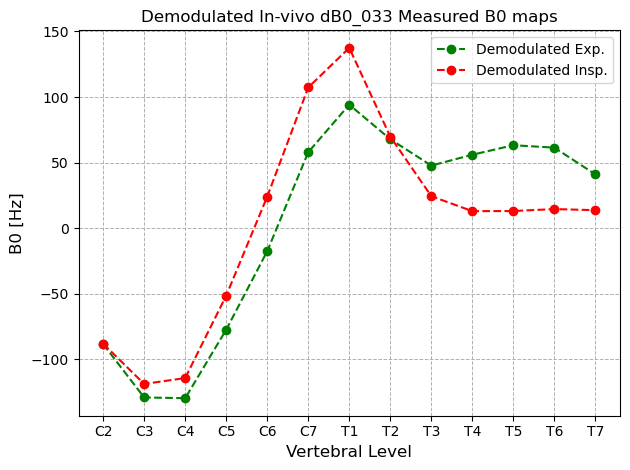

In [66]:
plt.plot(vertebrae_levelsC2_T7, demod_exp_metrics_data, marker = 'o', linestyle = '--', label = "Demodulated Exp.", color = "green")
plt.plot(vertebrae_levelsC2_T7, dmod_insp_metrics_data, marker = 'o', linestyle = '--', label = "Demodulated Insp.", color = "red")

plt.title(f"Demodulated In-vivo {participant_id} Measured B0 maps")
plt.xlabel('Vertebral Level', fontsize=12)
plt.ylabel('B0 [Hz]', fontsize=12)
plt.legend()
# Customize grid and display
plt.grid(True, which='both', linestyle='--', linewidth=0.7)
plt.tight_layout()

# Show the plot
plt.show()

### <span style="color:#14EFFA"> Initial B0 simulation </span>

In [2]:
path_to_chi_to_fm_fft = r"C:\Users\Admin\Documents\msc_project\susceptibility-to-fieldmap-fft"
sys.path.append(path_to_chi_to_fm_fft)
from functions import compute_fieldmap

In [3]:
path_to_dmod_msk = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\cord_mask.nii.gz"
path_to_chimap = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\output\sub-1_sus_phantom.nii.gz"
path_to_segs = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\final_sorted_all_labels.nii.gz"
path_to_sim_metric_msk = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\cord_mask_labeled.nii.gz"

gamma_bar = 42.58 # MHz/T
B0 = 3 # [T]

central_freq_exp = 123.249489 # in MHz, the inspiration Central Frequency was: 123.248999 MHz
B0_used_scanner = central_freq_exp /gamma_bar
print("The B0 to use in the simulation should be: ", B0_used_scanner, "T")

chi_dist, image_res, affine_matrix = compute_fieldmap.load_sus_dist(path_to_chimap)
sim_chi_img = nib.load(path_to_chimap)
sim_chi_data = sim_chi_img.get_fdata()

# Load segmentation labels that create the chimaps
ROI_img = nib.load(path_to_segs)
ROI_data = ROI_img.get_fdata()

# Find indices with the labels we want to update
ind_trachea = np.where((ROI_data == 113))
ind_lungs = np.where((ROI_data == 12))

dmod_sim_mask = nib.load(path_to_dmod_msk).get_fdata()
metric_sim_mask = nib.load(path_to_sim_metric_msk).get_fdata()

vertebra_label_map = {"C1": 1, "C2": 2, "C3": 3, "C4": 4, "C5": 5, "C6": 6, "C7": 7, "T1": 8, "T2": 9, "T3": 10, "T4": 11, "T5": 12, "T6": 13, "T7": 14, "T8": 15}
vertebrae_levels_opt =  ['C2','C3','C4','C5','C6','C7','T1','T2','T3','T4','T5','T6','T7'] # From 2 to 14

The B0 to use in the simulation should be:  2.8945394316580555 T


In [4]:
raw_sim_B0_metrics_path = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\sub-1_simulated_custom_mean_per_level_1_15.csv"
raw_sim_metrics_df = pd.read_csv(raw_sim_B0_metrics_path)

sim_metrics_df = (
    raw_sim_metrics_df
    .loc[
        raw_sim_metrics_df["VertLevel"].between(
            2,
            14,
            inclusive="both",
        )
    ]
    .sort_values("VertLevel")
    .reset_index(drop=True)
)

raw_sim_metrics_data = sim_metrics_df['WA()']
raw_sim_metrics_data

0    -3.351218
1    -3.547142
2    -3.519980
3    -3.204624
4    -2.692292
5    -2.078986
6    -1.706277
7    -1.737973
8    -1.810323
9    -1.797593
10   -1.796357
11   -1.873665
12   -1.929355
Name: WA(), dtype: float64

In [ ]:
# Now to go from ppm to Hz we can:
raw_sim_metrics_data_Hz = raw_sim_metrics_data * central_freq_exp # Because this is in MHz is same as doing * B0 * gamma_bar
raw_sim_metrics_data_Hz

0    -413.034093
1    -437.181511
2    -433.833797
3    -394.966558
4    -331.822149
5    -256.232884
6    -210.296891
7    -214.203374
8    -223.120425
9    -221.551498
10   -221.399091
11   -230.927248
12   -237.790938
Name: WA(), dtype: float64

In [6]:
selected_sim_dmod_mask = np.isin(
    metric_sim_mask,
    [
        vertebra_label_map[level]
        for level in vertebrae_levels_opt
    ],
).astype(np.uint8)

In [7]:
initial_b0_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\sub-1_fm_sim_custom_full_z_halfxy_dim.nii.gz").get_fdata()
dmod_sim_value = np.mean(initial_b0_data[selected_sim_dmod_mask==1]) * 123.248952 
dmod_sim_metrics_data_Hz = raw_sim_metrics_data_Hz - dmod_sim_value
dmod_sim_metrics_data_Hz

0    -109.071823
1    -133.219240
2    -129.871526
3     -91.004287
4     -27.859878
5      47.729386
6      93.665379
7      89.758897
8      80.841846
9      82.410773
10     82.563179
11     73.035023
12     66.171332
Name: WA(), dtype: float64

In [70]:
# Export demodulated metrics to CSV
dmod_sim_metrics_data_Hz.to_csv(
    r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\sub-1_DEMOD_simulated_custom_mean_per_level_1_15.csv",
    index=False,
    header=["dmod_B0_Hz"],
)

#  <span style="color:#C133FF"> *Direct optimization!* </span> 

In [8]:
import importlib
import utils.tools as tools_module

In [9]:
importlib.reload(tools_module)

vertebral_response = (
    tools_module.vertebral_response
)

extract_demodulated_sc_profile = (
    tools_module.extract_demodulated_sc_profile
)

In [10]:
trachea_response = vertebral_response(
    roi_label=113,
    roi_data=ROI_data,
    image_res=image_res,
    central_freq=central_freq_exp,
    dmod_mask=selected_sim_dmod_mask,
    metric_mask=metric_sim_mask,
    vertebral_levels=vertebrae_levels_opt,
    vertebra_label_map=vertebra_label_map,
    buffer = (150, 150, 400),
    mode='constant'
)

lung_response = vertebral_response(
    roi_label=12,
    roi_data=ROI_data,
    image_res=image_res,
    central_freq=central_freq_exp,
    dmod_mask=selected_sim_dmod_mask,
    metric_mask=metric_sim_mask,
    vertebral_levels=vertebrae_levels_opt,
    vertebra_label_map=vertebra_label_map,
    buffer = (150, 150, 400),
    mode='constant'
)

label_names = {
    0: "External air",
    5: "Brain",
    7: "Intervertebral disc",
    9: "Skeletal muscle",
    10: "Skull",
    11: "Spine bone",
    12: "Lungs",
    14: "SC",
    113: "Trachea",
    117: "Sinus",
    119: "Ear canal",
    264: "Body",
}

In [11]:
lung_label = 12
trachea_label = 113

chi_trachea_fixed = 0.27

fixed_chi_map = sim_chi_data.copy()

# Here now, we remove the lung label
fixed_chi_map[ROI_data == lung_label] = 0.0
fixed_chi_map[ROI_data == trachea_label] = (
    chi_trachea_fixed
)

# Because the lung label is removed, we can now extract the demodulate SC profile without the lungs contribution and added after using chi_lung * lung_response !!
fixed_profile = extract_demodulated_sc_profile(
    chi_map=fixed_chi_map,
    image_res=image_res,
    central_freq=central_freq_exp,
    dmod_mask=selected_sim_dmod_mask,
    metric_mask=metric_sim_mask,
    vertebral_levels=vertebrae_levels_opt,
    vertebra_label_map=vertebra_label_map,
    buffer = (150, 150, 400),
    mode='constant'
)

In [71]:
# This is the participants measured profile!
# We can switch between average, exp and insp:
# demod_avg_respiration
# demod_exp_metrics_data
# dmod_insp_metrics_data
measured_profile = np.asarray(
    demod_avg_respiration,
    dtype=float,
)
measured_profile

array([ -88.36782887, -124.10277985, -122.1364296 ,  -64.5575634 ,
          3.1690633 ,   82.58201484,  115.83086337,   68.78358555,
         36.00680467,   34.43357443,   38.10188918,   37.93810166,
         27.29193878])

In [72]:
# This tells us how much the the chi lung response needs to be to match the measured profile
target_for_lung = (
    measured_profile
    - fixed_profile
)

In [73]:
# Unconstrained analytical solution
chi_lung_unconstrained = (
    np.dot(
        lung_response,
        measured_profile - fixed_profile,
    )
    / np.dot(
        lung_response,
        lung_response,
    )
)

print(
    "Unconstrained lung susceptibility:",
    f"{chi_lung_unconstrained:.4f} ppm",
)

Unconstrained lung susceptibility: -1.2571 ppm


In [74]:
profile_unconstrained = (
    fixed_profile
    + chi_lung_unconstrained * lung_response
)

In [75]:
residual_unconstrained = (
    profile_unconstrained
    - measured_profile
)

rmse_unconstrained = np.sqrt(
    np.mean(residual_unconstrained**2)
)

print(
    "Unconstrained RMSE:",
    f"{rmse_unconstrained:.4f} Hz",
)


Unconstrained RMSE: 7.2517 Hz


In [76]:
residual_initial= (
    dmod_sim_metrics_data_Hz
    - measured_profile
)

rmse_initial = np.sqrt(
    np.mean(residual_initial**2)
)

print(
    "Initial RMSE:",
    f"{rmse_initial:.4f} Hz",
)

Initial RMSE: 32.1200 Hz


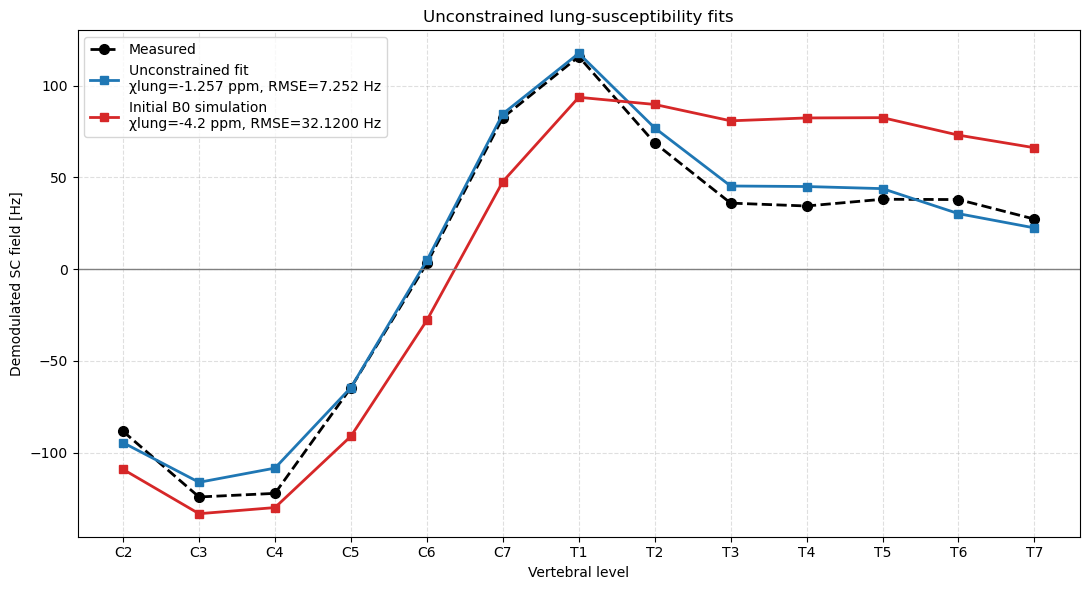

In [77]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    vertebrae_levels_opt,
    measured_profile,
    marker="o",
    markersize=7,
    linestyle="--",
    linewidth=2,
    color="black",
    label="Measured",
)

ax.plot(
    vertebrae_levels_opt,
    profile_unconstrained, #dmod_profile_unconstrained
    marker="s",
    markersize=6,
    linewidth=2,
    color="tab:blue",
    label=(
        "Unconstrained fit\n"
        f"χlung={chi_lung_unconstrained:.3f} ppm, "
        f"RMSE={rmse_unconstrained:.3f} Hz"
    ),
)

ax.plot(
    vertebrae_levels_opt,
    dmod_sim_metrics_data_Hz, #dmod_profile_unconstrained
    marker="s",
    markersize=6,
    linewidth=2,
    color="tab:red",
    label=(
        "Initial B0 simulation\n"
        f"χlung={-4.2} ppm, "
       f"RMSE={rmse_initial:.4f} Hz"
    ),
)


ax.axhline(
    0,
    color="gray",
    linewidth=1,
)

ax.set_xlabel("Vertebral level")
ax.set_ylabel("Demodulated SC field [Hz]")

ax.set_title(
    "Unconstrained "
    "lung-susceptibility fits"
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.4,
)

ax.legend()

fig.tight_layout()
plt.show()

### Saving final fit

In [78]:
fit_results_df = pd.DataFrame({
    "VertebralLevel": vertebrae_levels_opt,
    "MeasuredProfile_Hz": measured_profile,
    "FittedProfile_Hz": profile_unconstrained,
    "Residual_Hz": residual_unconstrained,
})

fit_results_df["FittedLungChi_ppm"] = (
    chi_lung_unconstrained
)

fit_results_df["FitRMSE_Hz"] = (
    rmse_unconstrained
)

fit_results_df

,VertebralLevel,MeasuredProfile_Hz,FittedProfile_Hz,Residual_Hz,FittedLungChi_ppm,FitRMSE_Hz
0,C2,-88.367829,-94.522668,-6.154839,-1.257129,7.251725
1,C3,-124.102780,-116.107316,7.995463,-1.257129,7.251725
2,C4,-122.136430,-108.368623,13.767807,-1.257129,7.251725
3,C5,-64.557563,-64.457956,0.099608,-1.257129,7.251725
4,C6,3.169063,4.828919,1.659856,-1.257129,7.251725
5,C7,82.582015,84.650305,2.068290,-1.257129,7.251725
6,T1,115.830863,117.600764,1.769901,-1.257129,7.251725
7,T2,68.783586,76.968573,8.184987,-1.257129,7.251725
8,T3,36.006805,45.328773,9.321968,-1.257129,7.251725
9,T4,34.433574,45.040969,10.607395,-1.257129,7.251725


In [79]:
fit_results_csv = (
    r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sub-01_lung_chi_avg_respiration_unconstrained_fit.csv"
)

fit_results_df.to_csv(
    fit_results_csv,
    index=False,
)

print(f"Saved fit results to:\n{fit_results_csv}")

Saved fit results to:
R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sub-01_lung_chi_avg_respiration_unconstrained_fit.csv


### Debug

In [58]:
print(
    "Least-squares orthogonality:",
    np.dot(lung_response, residual_unconstrained)
)

Least-squares orthogonality: -2.8421709430404007e-13


The closer it is to zero then it means the LS results is truly the LSQ minimum for the curred fixed_profile vs lung_response